In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import AxesGrid
from salvaged import *
run = '3me9r-3/'
datadir = '../data/'+run
prefix=''

In [2]:
snapshot = 15
t_eps=0.0001
ThisPatch = RamsesMHDPatch
#ThisPatch = Stagger2eMHDPatch
to_skip = []
extended = False
verbose=False
gamma = 1.4
orbit_radius_au = 1.0
omega = [0.0,0.0,1.0]
omega[2] = omega[2]*2.*np.pi*sc.scaling().t/sc.yr
pl_pos= [0.0,1.0,0.0]    
patches = get_data(snap = snapshot,datadir=datadir, ThisPatch=ThisPatch, skip=to_skip)

239 patches collected for snapshot 15


yt : [INFO     ] 2017-04-05 18:07:11,643 Parameters: current_time              = 2650.0
yt : [INFO     ] 2017-04-05 18:07:11,645 Parameters: domain_dimensions         = [48 48 48]
yt : [INFO     ] 2017-04-05 18:07:11,646 Parameters: domain_left_edge          = [-1000000. -1000000. -1000000.]
yt : [INFO     ] 2017-04-05 18:07:11,648 Parameters: domain_right_edge         = [ 1000000.  1000000.  1000000.]
yt : [INFO     ] 2017-04-05 18:07:11,649 Parameters: cosmological_simulation   = 0.0
yt : [INFO     ] 2017-04-05 18:07:12,397 xlim = -4708.836917 4708.836917
yt : [INFO     ] 2017-04-05 18:07:12,399 ylim = -9417.673835 9417.673835
yt : [INFO     ] 2017-04-05 18:07:12,401 xlim = -4708.836917 4708.836917
yt : [INFO     ] 2017-04-05 18:07:12,402 ylim = -9417.673835 9417.673835
yt : [INFO     ] 2017-04-05 18:07:12,403 Making a fixed resolution buffer of (('gas', 'temperature')) 800 by 800



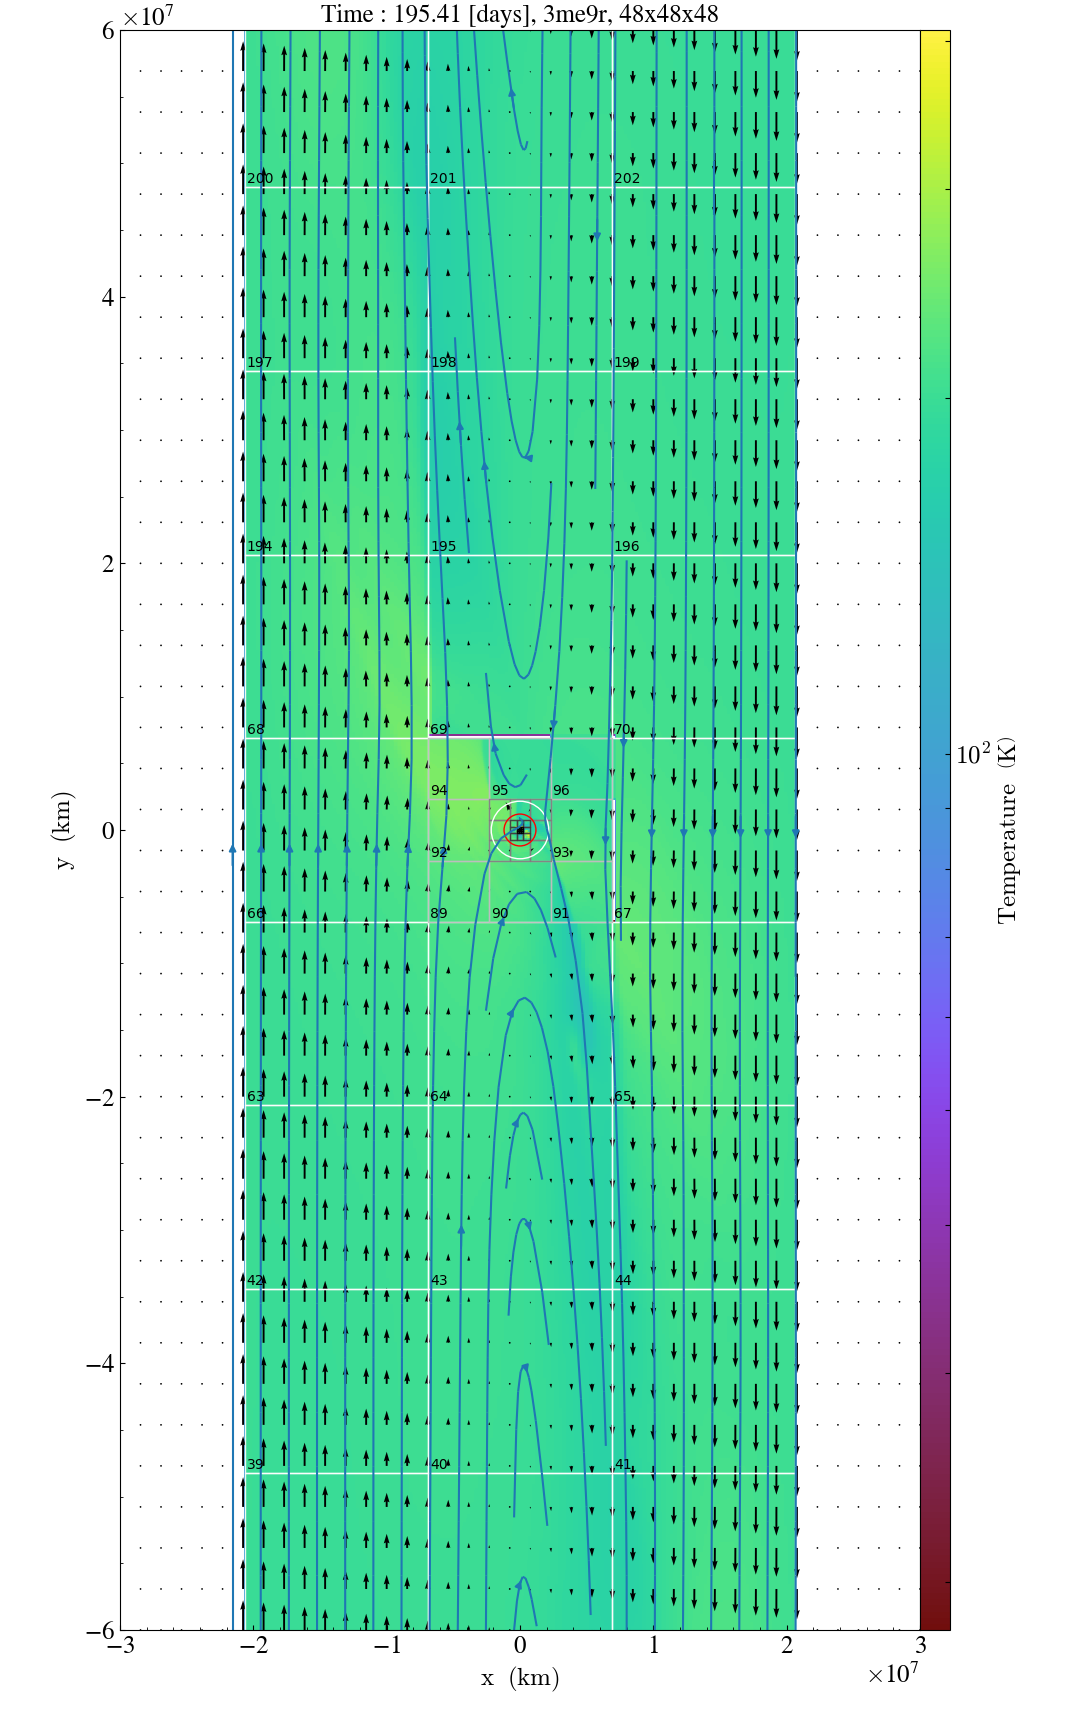

In [4]:
dic=make_yt_dict(patches)
n=patches[0].n
sz=1000000
pl_rad=1.3480656 * 9.
#pl_rad=1.0 * 3
#pl_rad = 0.5376369 * 9.
pl_mass=3.0
csound=1.0
restart_time = 2500.
time = patches[0].time+restart_time
bond_rad = pl_mass*sc.scaling().g/csound**2
hill_rad = (pl_mass*sc.scaling().g/(3.*omega[2]**2))**0.333333
ds = load_yt(dic,n,sz, time=time)
frc_time = 1000.
frc_force = 1.0
f_sc = 1-np.exp(-(time/frc_time)**2)*frc_force
#fig = plt.figure()

slc=yt.SlicePlot(ds=ds,axis="z",fields=["temperature"],center=[0,0,0],width = ((6e7,'km'),(12e7,'km')))
slc.annotate_velocity(factor=20, normalize=False)
slc.annotate_streamlines('velocity_x', 'velocity_y', factor=16,field_color=None)
slc.time_unit=sc.scaling().t
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=1, circle_args={'color':'magenta'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=pl_rad, circle_args={'color':'black'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=bond_rad, circle_args={'color':'red'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=hill_rad, circle_args={'color':'white'})
slc.current_time=patches[0].time*sc.scaling().t/3600./24.
#slc.annotate_title("Time : %.2f [days]" % ((patches[0].time+restart_time)*sc.scaling().t/3600./24.)+" Friction parameter: %.4f" %f_sc)
slc.annotate_title("Time : %.2f [days], 3me9r, 48x48x48" % ((patches[0].time+restart_time)*sc.scaling().t/3600./24.))#+" Friction parameter: %.4f" %f_sc)
#slc.set_zlim('density',6e-12,3e-11)
#slc.annotate_timestamp()
#slc.zoom(10)
slc.annotate_grids(alpha=0.9, draw_ids=True)
#slc.annotate_timestamp()
slc.show()

yt : [INFO     ] 2017-04-05 17:43:51,957 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



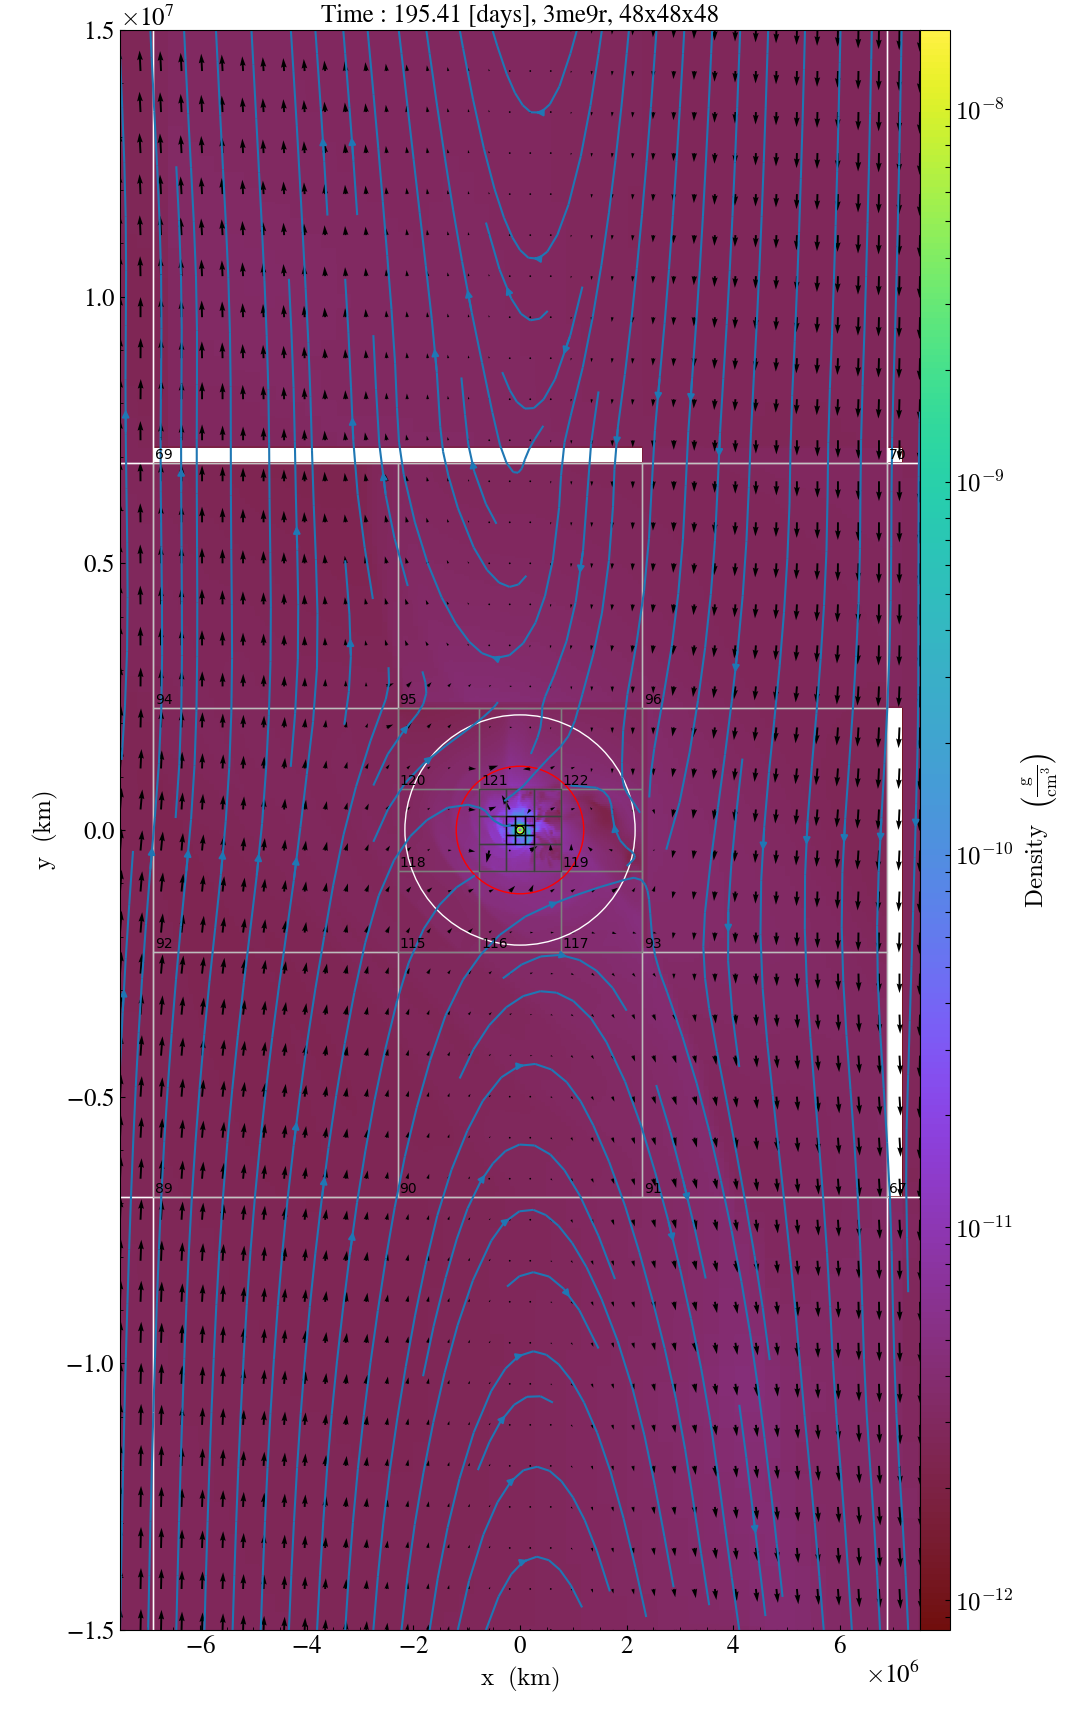

In [5]:
slc.zoom(2)
#slc.set_zlim('temperature',150,250)
#slc.set_zlim('density',2e-13,4e-14)
#slc.set_zlim('e',8e-14,2e-11)
#slc.annotate_grids()
slc.show()

In [252]:
slc.save('3me9r-energy-3.png')

yt : [INFO     ] 2017-04-03 09:24:26,192 Saving plot 3me9r-energy-3.png


['3me9r-energy-3.png']

In [38]:
def load_long_yt(dc,nx,sz=100,refine_by=3,geometry="cartesian",mass_unit=sc.scaling().m,length_unit=sc.scaling().l,
            time_unit=sc.scaling().t,velocity_unit=sc.scaling().v,periodicity=(False,False,False),time=0):
    ds=yt.load_amr_grids(dc,nx,
                       bbox=np.array([[-sz,sz],[-sz*3,sz*3],[-sz,sz]]),
                       refine_by=3,
                       geometry="cartesian",
                       mass_unit=sc.scaling().m,
                       length_unit=(sc.scaling().l,"km"),
                       velocity_unit=sc.scaling().v,
                       time_unit=sc.scaling().t,
                       sim_time = time,
                       periodicity=(False,False,False))
    return ds

In [ ]:
my_ray = ds.ortho_ray(0,(0,0))
ray_sort = np.argsort(my_ray["t"])
density = my_ray["density"][ray_sort]

In [42]:
hill_rad

338.7725842785517

In [203]:
np.exp(-1.)

0.36787944117144233

In [6]:
sc.scaling().temp

242.2828999782719

In [16]:
ee=ds.all_data()

In [120]:
patches[0].velx.max()

3.2248369308263136e-08

In [12]:
gn =patches[0].gn; ng = patches[0].nghost

In [13]:
u=[a-b for a,b in zip(gn,ng)]

In [21]:
om = omega[2] * np.pi* sc.scaling().t / sc.yr
d0 = 3e-12

om

[array([[-41.31358636, -41.97537382, -42.6709973 , ..., -43.34507759,
         -46.03222886, -51.69649208],
        [-40.55425349, -41.32289755, -41.93077684, ..., -42.3299653 ,
         -44.79485703, -51.38390131],
        [-39.70342968, -40.10057365, -40.29059421, ..., -40.31905604,
         -43.77457008, -51.08592603],
        ..., 
        [-31.11197762, -28.97589544, -26.3394391 , ..., -22.38928413,
         -25.09154891, -27.901655  ],
        [-30.98386243, -28.87682106, -26.25213822, ..., -22.28911747,
         -24.94691731, -27.71784235],
        [-30.86473909, -28.78982692, -26.18322179, ..., -22.19863252,
         -24.80035471, -27.54049199]]),
 array([[-41.23350177, -41.84101286, -42.37113009, ..., -39.47061702,
         -42.88210952, -54.23790999],
        [-40.57827441, -41.11969043, -41.61791986, ..., -38.41087516,
         -41.73895717, -53.89113847],
        [-39.12319073, -38.4536872 , -36.44004402, ..., -32.78092129,
         -39.51820087, -53.16168213],
        ...,

In [26]:
patches[33].id

99

In [3]:
snap = 15

In [5]:
"*%.4i.txt"%snap

'*0015.txt'